# 02 · Model training and evaluation, step by step

Runs the project's protocol (`churnlens.training.run_experiment`) on the demo data and walks through each result. It uses the same library code as `train_model.py` — there is no second implementation — and writes **nothing** to `models/` or `reports/` (artefacts stay in memory). Requires the Telco CSV (`../data/README.md`).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")          # run from the notebooks/ folder, no installation needed
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churnlens.config import load_config

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False, "axes.spines.right": False})
config = load_config()

In [2]:
from churnlens.data import load_demo_dataset, prepare_dataset
from churnlens.training import run_experiment

prepared = prepare_dataset(load_demo_dataset(config), config.data.target, positive_label=config.data.positive_label,
                           id_column=config.data.id_column, config=config)
result = run_experiment(prepared, config, engineer=True)
print("train / test rows:", len(result.train_index), "/", len(result.test_index))
print("selected:", result.selected_label); print(result.selection_note)

train / test rows: 5634 / 1409
selected: Logistic Regression
Best mean CV average_precision (0.6672), and the simplest eligible model.


## 1. Models on identical cross-validation folds (training split only)

Five stratified folds, the same for every model, preprocessing re-fitted inside each fold. This table is what the model is chosen from. The test set has not been touched.

In [3]:
cols = ["label", "roc_auc_mean", "roc_auc_std", "average_precision_mean", "average_precision_std",
        "f1_mean", "log_loss_mean", "brier_score_mean", "fit_time_s_mean"]
result.comparison[cols].round(4)

,label,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,f1_mean,log_loss_mean,brier_score_mean,fit_time_s_mean
0,Dummy (class prior),0.5000,0.0000,0.2654,0.0001,0.0000,0.5786,0.1949,0.2906
1,Logistic Regression,0.8479,0.0103,0.6672,0.0201,0.5931,0.4142,0.1342,0.3810
2,Decision Tree,0.8275,0.0081,0.6110,0.0226,0.5691,0.5046,0.1420,0.2239
3,Random Forest,0.8452,0.0105,0.6608,0.0260,0.5763,0.4163,0.1350,1.9734
4,Hist. Gradient Boosting,0.8444,0.0092,0.6641,0.0199,0.5838,0.4173,0.1356,1.7616


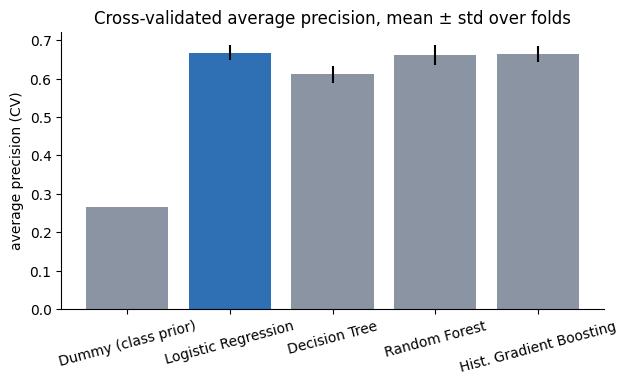

In [4]:
fig, ax = plt.subplots()
c = result.comparison
ax.bar(c["label"], c["average_precision_mean"], yerr=c["average_precision_std"],
       color=["#2f6fb3" if m == result.selected_key else "#8a94a3" for m in c["model"]])
ax.set_ylabel("average precision (CV)"); ax.set_title("Cross-validated average precision, mean ± std over folds")
plt.xticks(rotation=15); plt.show()

## 2. Probabilities and calibration (out-of-fold)

{'mean_predicted': 0.2654, 'observed_rate': 0.2654, 'brier_score': 0.1342, 'expected_calibration_error': 0.0109}


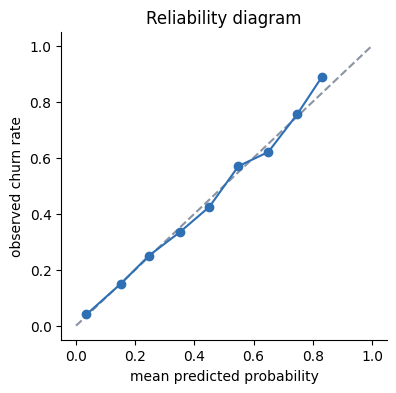

In [5]:
cal = result.calibration_oof
print({k: round(v, 4) for k, v in cal.items() if k != "bins"})
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], "--", color="#8a94a3"); ax.plot(cal["bins"].mean_predicted, cal["bins"].observed_rate, "o-", color="#2f6fb3")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed churn rate"); ax.set_title("Reliability diagram"); plt.show()

## 3. Decision threshold (chosen on out-of-fold training predictions)

In [6]:
from churnlens.evaluation import threshold_table
table = threshold_table(result.oof["y_true"], result.oof["proba"])
print(result.threshold.description)
table[["threshold", "flagged", "fp", "fn", "precision", "recall", "f1"]].round(3)

Threshold 0.33 maximises F1 (balance of precision and recall) on out-of-fold predictions of the training set (the test set is not used).


,threshold,flagged,fp,fn,precision,recall,f1
0,0.05,4086,2629,38,0.357,0.975,0.522
1,0.10,3485,2077,87,0.404,0.942,0.565
2,0.15,3107,1745,133,0.438,0.911,0.592
3,0.20,2700,1409,204,0.478,0.864,0.615
4,0.25,2381,1166,280,0.510,0.813,0.627
5,0.30,2120,974,349,0.541,0.767,0.634
6,0.35,1882,806,419,0.572,0.720,0.637
7,0.40,1618,640,517,0.604,0.654,0.628
8,0.45,1409,513,599,0.636,0.599,0.617
9,0.50,1192,395,698,0.669,0.533,0.593


## 4. Final test evaluation — used once, selected model only

In [7]:
print("threshold:", result.threshold.threshold)
pd.DataFrame({"value": result.test_metrics, "at threshold 0.5": result.test_metrics_at_default}).join(
    pd.DataFrame(result.test_metrics_ci, index=["ci_low", "ci_high"]).T).round(3)

threshold: 0.33


,value,at threshold 0.5,ci_low,ci_high
roc_auc,0.842,0.842,0.823,0.865
average_precision,0.634,0.634,0.584,0.689
precision,0.539,0.655,0.496,0.582
recall,0.725,0.532,0.681,0.773
f1,0.618,0.587,0.583,0.655
balanced_accuracy,0.750,0.715,NaN,NaN
accuracy,0.762,0.801,NaN,NaN
log_loss,0.420,0.420,NaN,NaN
brier_score,0.138,0.138,NaN,NaN


## 5. Errors on the test set

In [8]:
from churnlens.error_analysis import classify_outcomes, confusion_frame, error_metrics, error_profile
test = result.test_predictions
outcomes = classify_outcomes(test["y_true"], test["proba"], result.threshold.threshold)
print(confusion_frame(outcomes))
print({k: round(v, 3) for k, v in error_metrics(outcomes).items()})
X_test = prepared.frame.iloc[result.test_index][result.schema.names].reset_index(drop=True)
print("\nFalse negatives (missed churners) vs true positives - features that differ most:")
error_profile(X_test, outcomes, "FN").head(6)

                Predicted: stays  Predicted: churns
Actual: stays                803                232
Actual: churns               103                271
{'tp': 271, 'fp': 232, 'fn': 103, 'tn': 803, 'precision': 0.539, 'recall': 0.725, 'specificity': 0.776, 'false_positive_rate': 0.224, 'false_negative_rate': 0.275, 'negative_predictive_value': 0.886, 'flagged_share': 0.357}

False negatives (missed churners) vs true positives - features that differ most:


,feature,kind,effect_size,detail
0,tenure,numeric,0.858998,mean 28.46 vs 11.90
1,TotalCharges,numeric,0.678757,mean 2367.66 vs 1033.21
2,MonthlyCharges,numeric,-0.514562,mean 62.82 vs 76.55
3,TechSupport,categorical,-0.490273,'No': 42% vs 91%
4,OnlineSecurity,categorical,-0.486583,'No': 42% vs 90%
5,SeniorCitizen,numeric,-0.463247,mean 0.13 vs 0.31


## 6. What the model relies on — associations, not causes

In [9]:
from churnlens.explainability import native_importance
native = native_importance(result.pipeline)
print(native[["label", "value", "odds_ratio"]].head(8).round(3).to_string(index=False))
result.permutation.head(8).round(4)

                        label  value  odds_ratio
                       tenure -1.297       0.273
        InternetService = DSL -0.676       0.509
InternetService = Fiber optic  0.644       1.905
               MonthlyCharges -0.544       0.580
   TenureSegment = 37+ months  0.484       1.623
               ContractMonths -0.467       0.627
 TenureSegment = 13-24 months -0.374       0.688
        PaperlessBilling = No -0.339       0.713


,feature,importance_mean,importance_std
0,tenure,0.1991,0.0153
1,InternetService,0.0735,0.0148
2,MonthlyCharges,0.0539,0.0101
3,Contract,0.0423,0.0184
4,StreamingMovies,0.0098,0.0081
5,TechSupport,0.0075,0.0061
6,TotalCharges,0.0073,0.0088
7,OnlineSecurity,0.0069,0.0088


## 7. A retention scenario (illustrative assumptions, not estimates)

In [10]:
from churnlens.retention_simulator import Assumptions, simulate_strategies, break_even_probability
e = config.economics
a = Assumptions(e.cost_per_contact, e.value_per_retained_customer, e.success_rate, e.budget, e.max_contacts)
print("break-even probability p* =", round(break_even_probability(a.cost_per_contact, a.value_per_retained, a.success_rate), 2))
simulate_strategies(test["proba"].to_numpy(), a, risk_threshold=e.risk_threshold, top_k=e.top_k,
                    actual=test["y_true"].to_numpy())[["strategy", "contacted", "within_limits", "total_cost",
                    "expected_churners_targeted", "gross_benefit", "net_benefit", "roi"]].round(2)

break-even probability p* = 0.3


,strategy,contacted,within_limits,total_cost,expected_churners_targeted,gross_benefit,net_benefit,roi
0,No campaign,0,True,0.0,0.00,0.00,0.00,NaN
1,Contact everyone,1409,False,21135.0,376.53,18826.68,-2308.32,-0.11
2,Top 300 by risk,300,False,4500.0,198.30,9914.77,5414.77,1.20
3,Risk >= 0.50,304,False,4560.0,200.30,10015.20,5455.20,1.20
4,Budget-limited,200,True,3000.0,143.26,7162.79,4162.79,1.39


Net benefit = V × R × Q − N × C is conditional on the cost, value and success-rate assumptions above; none comes from the data. See `../docs/ECONOMIC_ASSUMPTIONS.md`.